# 10 · Final model: save it and demo it

**Owner:** Samina

Notebook 08 chose **ElasticNet** as the final model: it ties for the lowest error on unseen batteries
(LOCO MAE 4.25), has the smallest gap between random and grouped testing, and its coefficients can be explained.

This notebook does two things:

1. **Saves the final model.** ElasticNet is trained on all 15 batteries with the same pipeline and settings grid as
   notebook 07, then saved to `models/elasticnet_final.joblib` together with a small info file.
2. **Demo.** A saved model is loaded back and used to predict batteries it has never seen. For an honest demo we use
   the **3 locked test batteries** (2_009, 2_092, 2_098): a second copy of the model is trained only on the other 12
   batteries and saved as `models/elasticnet_demo_12cells.joblib`, so the 3 demo batteries were never used for
   training or tuning. Its score must match the locked check in notebook 08.

All data, inputs and preprocessing come from the shared protocol (`src/evaluation.py`); nothing is chosen here.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np, pandas as pd
import joblib, sklearn
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import src.evaluation as ev
warnings.filterwarnings("ignore")

MODELS = ROOT / "models"
FIG = ROOT / "results" / "final_model" / "figures"
MODELS.mkdir(exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

df = ev.load_labelled()
NUM, CAT = ev.main_features()
INPUTS = NUM + CAT + ["cell_id"]          # cell_id is only used by the pruner's ranking, never as a model input
print(f"{len(df)} labelled check-ups | {df.cell_id.nunique()} batteries | inputs: {len(NUM)} numeric + {CAT}")
print("scikit-learn", sklearn.__version__)

306 labelled check-ups | 15 batteries | inputs: 42 numeric + ['schedule']
scikit-learn 1.9.1


## 1. Train and save the final model

Same model and settings grid as notebook 07. The penalty settings are chosen with a 5-fold split that keeps whole
batteries together (`GroupKFold`), and the pipeline fits pruning, clipping, imputation and scaling inside it.

In [2]:
GRID = {"model__alpha": list(np.logspace(-3, 1, 9)), "model__l1_ratio": [0.2, 0.5, 0.8]}

def train_elasticnet(rows: pd.DataFrame):
    pipe = ev.make_pipeline(ElasticNet(max_iter=50_000), NUM, CAT)
    search = GridSearchCV(pipe, GRID, cv=GroupKFold(5), scoring="neg_mean_absolute_error", n_jobs=-1)
    search.fit(rows[INPUTS], rows[ev.TARGET], groups=rows.cell_id)
    return search.best_estimator_, {k.removeprefix("model__"): float(v) for k, v in search.best_params_.items()}

def make_saveable(pipe):
    # The shared preprocessor picks the numeric columns with a small inner function, which Python cannot write to a
    # file. After training, the column lists are fixed, so we swap the function for those lists. Predictions do not
    # change (checked below); src/evaluation.py is left untouched.
    ct = pipe.named_steps["prep"].named_steps["columns"]
    ct.transformers = [(name, trans, ct._columns[i]) for i, (name, trans, _) in enumerate(ct.transformers)]
    return pipe

final_model, final_settings = train_elasticnet(df)
before = final_model.predict(df[INPUTS])
final_model = make_saveable(final_model)
assert np.allclose(before, final_model.predict(df[INPUTS])), "making the model saveable changed its predictions"
kept = list(final_model.named_steps["prep"].get_feature_names_out())

path = MODELS / "elasticnet_final.joblib"
joblib.dump(final_model, path)
info = {
    "model": "ElasticNet (scikit-learn Pipeline: redundancy pruning, clipping, median imputation, scaling, one-hot)",
    "target": "SOH (%) = 25 C reference capacity / the cell's first 25 C reference capacity x 100",
    "trained_on": f"{len(df)} check-ups from {df.cell_id.nunique()} batteries (all labelled rows)",
    "settings": final_settings,
    "input_columns": NUM + CAT,
    "features_kept_after_pruning": kept,
    "scikit_learn_version": sklearn.__version__,
    "expected_error_on_a_new_battery": "LOCO MAE 4.25 SOH points (notebook 07/08)",
}
(MODELS / "elasticnet_final_info.json").write_text(json.dumps(info, indent=2))
print(f"saved {path.relative_to(ROOT)}  ({path.stat().st_size / 1024:.1f} KB, under the 2 MB upload limit)")
print("chosen settings:", final_settings, "| features kept:", len(kept))

saved models/elasticnet_final.joblib  (15.5 KB, under the 2 MB upload limit)
chosen settings: {'alpha': 0.1, 'l1_ratio': 0.8} | features kept: 25


## 2. Demo: load a saved model and predict batteries it has never seen

The final model above has seen every battery, so it cannot be tested fairly. For the demo we train the same model on
the **12 development batteries only**, save it, load it back, and predict the **3 locked test batteries**.

In [3]:
split = pd.read_csv(ROOT / "results" / "preprocessed" / "split_assignment.csv")[["cell_id", "idtest", "split"]]
d = df.merge(split, on=["cell_id", "idtest"], validate="one_to_one")
dev, locked = d[d.split != "test"], d[d.split == "test"]
print("trained on:", dev.cell_id.nunique(), "batteries | demo batteries (never seen):", sorted(locked.cell_id.unique()))

demo_model, demo_settings = train_elasticnet(dev)
joblib.dump(make_saveable(demo_model), MODELS / "elasticnet_demo_12cells.joblib")
print("saved models/elasticnet_demo_12cells.joblib | settings:", demo_settings)

trained on: 12 batteries | demo batteries (never seen): ['2_009', '2_092', '2_098']


saved models/elasticnet_demo_12cells.joblib | settings: {'alpha': 0.31622776601683794, 'l1_ratio': 0.8}


In [4]:
# --- this is the demo: load the saved file and predict ---
model = joblib.load(MODELS / "elasticnet_demo_12cells.joblib")

def health_class(soh):
    return "Healthy (>=90)" if soh >= 90 else "Degraded (80-90)" if soh >= 80 else "EOL risk (<80)"

pred = model.predict(locked[INPUTS])
demo = locked[["cell_id", "profile", "rtp_index", "SOH"]].assign(predicted_SOH=pred.round(2))
demo["error"] = (demo.predicted_SOH - demo.SOH).round(2)
demo["true_class"] = demo.SOH.map(health_class)
demo["predicted_class"] = demo.predicted_SOH.map(health_class)

mae = mean_absolute_error(demo.SOH, demo.predicted_SOH)
print(f"MAE on the 3 unseen batteries: {mae:.2f} SOH points (RMSE {root_mean_squared_error(demo.SOH, demo.predicted_SOH):.2f})")
display(demo.groupby("cell_id").apply(lambda g: pd.Series({
    "profile": g.profile.iloc[0], "check-ups": len(g), "MAE": mean_absolute_error(g.SOH, g.predicted_SOH),
    "last true SOH": g.SOH.iloc[-1], "last predicted SOH": g.predicted_SOH.iloc[-1]})).round(2))

ref = pd.read_csv(ROOT / "results" / "baselines" / "holdout_check.csv").set_index("model").loc["ElasticNet (tuned)", "MAE"]
print(f"locked check in notebook 08: {ref:.2f} -> {'matches' if abs(ref - mae) < 0.01 else 'DIFFERS'}")

MAE on the 3 unseen batteries: 5.27 SOH points (RMSE 7.06)


,profile,check-ups,MAE,last true SOH,last predicted SOH
cell_id,,,,,
2_009,L03,21,2.16,87.21,87.63
2_092,L202,22,10.93,88.20,73.06
2_098,L209,22,2.58,87.80,82.50


locked check in notebook 08: 5.27 -> matches


In [5]:
# One check-up at a time, the way a battery-management system would use it
row = locked[locked.cell_id == "2_098"].iloc[[-1]]
p = model.predict(row[INPUTS])[0]
print(f"battery {row.cell_id.iloc[0]}, check-up {int(row.rtp_index.iloc[0])}: "
      f"predicted SOH {p:.1f}% ({health_class(p)}), true SOH {row.SOH.iloc[0]:.1f}% ({health_class(row.SOH.iloc[0])})")

battery 2_098, check-up 22: predicted SOH 82.5% (Degraded (80-90)), true SOH 87.8% (Degraded (80-90))


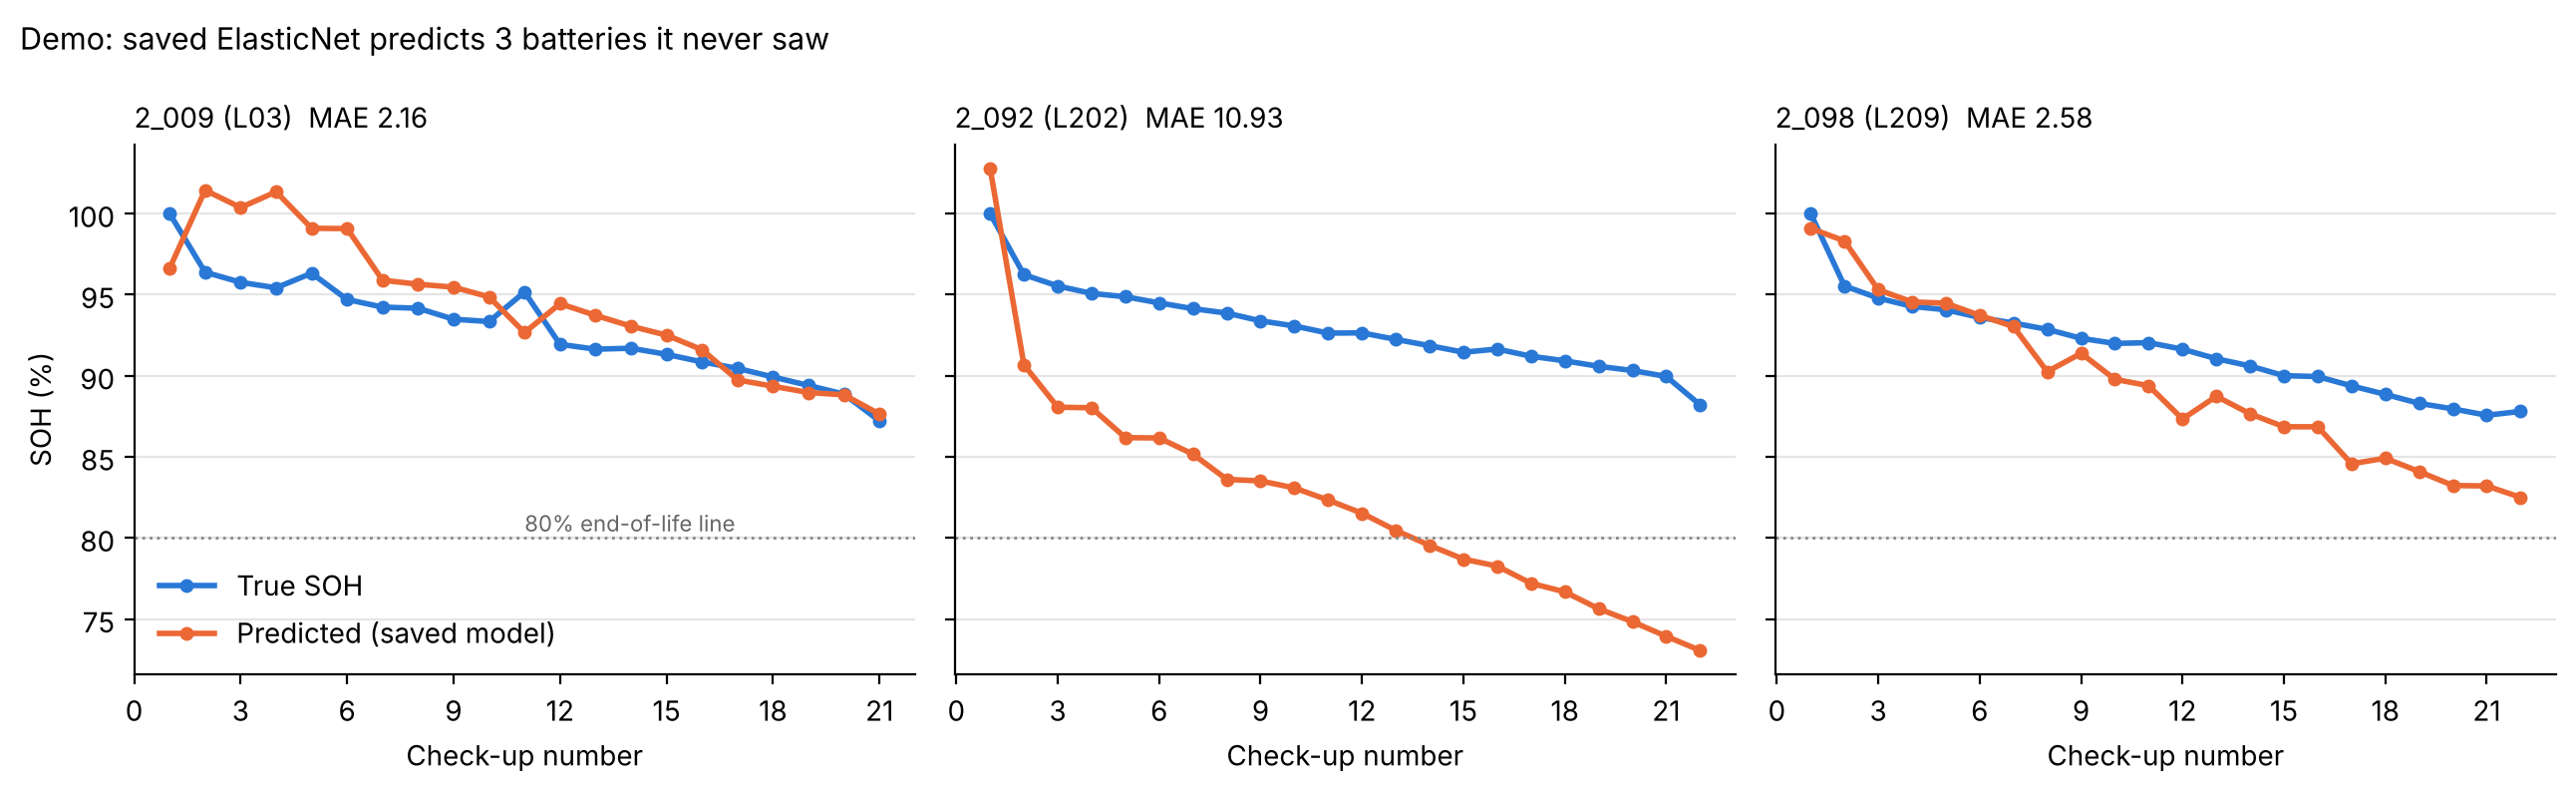

In [6]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (cell, g) in zip(axes, demo.groupby("cell_id")):
    g = g.sort_values("rtp_index")
    ax.plot(g.rtp_index, g.SOH, "-o", color="#2a78d6", lw=2, ms=4, label="True SOH")
    ax.plot(g.rtp_index, g.predicted_SOH, "-o", color="#eb6834", lw=2, ms=4, label="Predicted (saved model)")
    ax.axhline(80, color="#888", ls=":", lw=1)
    ax.set_title(f"{cell} ({g.profile.iloc[0]})  MAE {mean_absolute_error(g.SOH, g.predicted_SOH):.2f}",
                 loc="left", fontsize=10)
    ax.set_xlabel("Check-up number"); ax.yaxis.grid(True, color="#e5e5e5")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set_ylabel("SOH (%)")
axes[0].text(0.5, 80.4, "80% end-of-life line", fontsize=8, color="#666", transform=axes[0].get_yaxis_transform())
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("Demo: saved ElasticNet predicts 3 batteries it never saw", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "demo_locked_batteries.png", dpi=200); plt.show()
demo.to_csv(ROOT / "results" / "final_model" / "demo_predictions_locked_cells.csv", index=False)

## Summary

- **Saved model:** `models/elasticnet_final.joblib` (ElasticNet trained on all 15 batteries) plus
  `models/elasticnet_final_info.json` with its settings, inputs and scikit-learn version. It is small enough to upload
  directly (limit 2 MB).
- **Demo:** a model trained on 12 batteries was saved, loaded back and used to predict the 3 locked batteries it never
  saw. The error matches the locked check in notebook 08.
- **What the demo shows:** predictions follow the two familiar batteries (2_009, 2_098) closely. Battery 2_092 was aged
  under conditions no training battery covers (profile L202, held at low SoC), and the error is much larger there:
  the model predicts it is wearing out much faster than it really is.
  This is the same pattern as the main results: the model is reliable for familiar operating conditions and less
  reliable for new ones.
- To load the model elsewhere, use the same scikit-learn version (see the info file) and import `src` first, because the
  pipeline uses the project's own transformers.